Supplementary Figure: branch-specific stress tests

In [8]:
# ============================================================
# Supplementary Simulation — Branch-specific stress tests
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import isovita as iso
import isovita_simulation as isim


# ============================================================
# 1. Reference simulation configuration
# ============================================================

BRANCHES = (
    "discrete",
    "continuous",
)

SIGNAL_STRENGTHS = np.array(
    [0.05, 0.10, 0.20, 0.40, 0.80],
    dtype=float,
)

N_SAMPLES = 180
K = 4

# Two alternative genes at each signal strength.
GENES_PER_STRENGTH = 2

# 5 strengths × 2 genes = 10 alternatives.
N_ALT = (
    len(SIGNAL_STRENGTHS)
    * GENES_PER_STRENGTH
)

# Each stress-test dataset remains 50% null.
N_NULL = N_ALT
N_GENES = N_NULL + N_ALT

N_REPLICATES = 15

NOISE_SD = 0.30
NOISE_CORR = 0.10
BASELINE_SD = 0.22

ALPHA_FDR = 0.05

# 20 hypotheses per branch:
# minimum permutation p = 1 / 1001 ~= 0.001
# first BH threshold = 0.05 / 20 = 0.0025
N_PERMUTATIONS = 1000

N_JOBS = 8

BASE_SEED = 20260927


# ============================================================
# Discrete geometry
# ============================================================

STEP_LOCATIONS = (
    15.0,
    30.0,
    45.0,
    65.0,
)


# ============================================================
# Continuous geometry
# ============================================================

CONTINUOUS_SHAPES = (
    "linear",
    "sigmoid",
    "u_shape",
    "sinusoid",
)


# ============================================================
# Shared IsoVita configuration
# ============================================================

BALANCE_CONFIG = iso.BalanceConfig()

DISCRETE_CONFIG = iso.DiscreteConfig(
    alpha_fdr=ALPHA_FDR,
)

CONTINUOUS_CONFIG = iso.ContinuousConfig(
    alpha_fdr=ALPHA_FDR,
)


# ============================================================
# Reference transcript loading direction
# ============================================================

REFERENCE_LOADINGS = np.array(
    [1.00, 0.82, -0.92, -0.75],
    dtype=float,
)


# ============================================================
# Permutation-resolution check
# ============================================================

minimum_p = (
    1.0
    / (N_PERMUTATIONS + 1.0)
)

first_bh_threshold = (
    ALPHA_FDR
    / N_GENES
)

print(
    f"Genes per stress-test dataset: {N_GENES}"
)

print(
    "Minimum permutation p-value:",
    f"{minimum_p:.6f}",
)

print(
    "First BH threshold:",
    f"{first_bh_threshold:.6f}",
)

Genes per stress-test dataset: 20
Minimum permutation p-value: 0.000999
First BH threshold: 0.002500


In [9]:
# ============================================================
# 2. Simulation helpers
# ============================================================

def deterministic_seed_offset(
    *parts,
):
    """
    Deterministic integer offset from arbitrary labels.

    This avoids Python's randomized hash() while giving
    different stress conditions reproducible random streams.
    """
    text = "|".join(
        str(part)
        for part in parts
    )

    return sum(
        (i + 1) * ord(char)
        for i, char in enumerate(text)
    )


def make_loadings(
    rng,
):
    """
    Slightly perturb the reference compositional direction
    for each simulated alternative gene.
    """
    loading = (
        REFERENCE_LOADINGS
        + rng.normal(
            0.0,
            0.04,
            size=K,
        )
    )

    loading = (
        loading
        - loading.mean()
    )

    loading = (
        loading
        / np.max(
            np.abs(loading)
        )
    )

    return tuple(
        loading.tolist()
    )


def make_gene_baselines(
    rng,
):
    return tuple(
        rng.normal(
            0.0,
            BASELINE_SD,
            size=K,
        ).tolist()
    )


def make_continuous_component(
    shape,
    loadings,
    amplitude,
):
    """
    Construct one continuous-trajectory simulation component.
    """

    if shape == "linear":

        return isim.TemporalComponent(
            kind="linear",
            loadings=loadings,
            amplitude=float(
                amplitude
            ),
        )


    if shape == "sigmoid":

        return isim.TemporalComponent(
            kind="sigmoid",
            loadings=loadings,
            amplitude=float(
                amplitude
            ),
            params={
                "center": 42.0,
                "scale": 16.0,
            },
        )


    if shape == "u_shape":

        return isim.TemporalComponent(
            kind="u_shape",
            loadings=loadings,
            amplitude=float(
                amplitude
            ),
            params={
                "center": 42.5,
                "scale": 42.5,
            },
        )


    if shape == "sinusoid":

        return isim.TemporalComponent(
            kind="sinusoid",
            loadings=loadings,
            amplitude=float(
                amplitude
            ),
            params={
                "cycles": 1.0,
                "phase": 0.0,
            },
        )


    raise ValueError(
        f"Unknown continuous shape: {shape}"
    )


# ============================================================
# 3. Build one branch-specific stress-test dataset
# ============================================================

def make_branch_stress_scenarios(
    branch,
    geometry,
    replicate,
):
    """
    Build one stress-test dataset containing:

      - 10 age-null genes
      - 10 alternative genes
      - 2 alternatives at each of 5 signal strengths

    The discrete experiment varies changepoint location.
    The continuous experiment varies trajectory shape.
    """

    if branch not in BRANCHES:
        raise ValueError(
            f"Unknown branch: {branch}"
        )


    rng = np.random.default_rng(
        BASE_SEED
        + 100_000 * replicate
        + deterministic_seed_offset(
            branch,
            geometry,
            "scenario",
        )
    )


    scenarios = []
    truth_rows = []


    # --------------------------------------------------------
    # Null genes
    # --------------------------------------------------------

    for i in range(
        N_NULL
    ):

        gene_id = (
            f"R{replicate:03d}_"
            f"{branch.upper()}_"
            f"NULL_{i + 1:03d}"
        )


        scenarios.append(
            isim.IsoformScenario(
                gene_id=gene_id,
                label="Age-null",
                baselines=(
                    make_gene_baselines(
                        rng
                    )
                ),
                components=(),
                noise_sd=NOISE_SD,
                noise_corr=NOISE_CORR,
            )
        )


        truth_rows.append({
            "gene_id":
                gene_id,

            "truth_type":
                "null",

            "signal_strength":
                0.0,

            "geometry":
                geometry,

            "true_change_age":
                np.nan,
        })


    # --------------------------------------------------------
    # Alternative genes
    # --------------------------------------------------------

    for strength in (
        SIGNAL_STRENGTHS
    ):

        for gene_index in range(
            GENES_PER_STRENGTH
        ):

            gene_id = (
                f"R{replicate:03d}_"
                f"{branch.upper()}_"
                f"S{strength:g}_"
                f"G{gene_index + 1}_"
                f"{deterministic_seed_offset(geometry) % 10000:04d}"
            )


            loadings = (
                make_loadings(
                    rng
                )
            )


            # --------------------------------------------
            # Discrete truth
            # --------------------------------------------

            if branch == "discrete":

                change_age = float(
                    geometry
                )

                component = (
                    isim.TemporalComponent(
                        kind="step",
                        loadings=loadings,
                        amplitude=float(
                            strength
                        ),
                        params={
                            "change_age":
                                change_age,
                        },
                    )
                )

                true_change_age = (
                    change_age
                )


            # --------------------------------------------
            # Continuous truth
            # --------------------------------------------

            else:

                component = (
                    make_continuous_component(
                        geometry,
                        loadings,
                        strength,
                    )
                )

                true_change_age = np.nan


            scenarios.append(
                isim.IsoformScenario(
                    gene_id=gene_id,
                    label=str(
                        geometry
                    ),
                    baselines=(
                        make_gene_baselines(
                            rng
                        )
                    ),
                    components=(
                        component,
                    ),
                    noise_sd=NOISE_SD,
                    noise_corr=NOISE_CORR,
                )
            )


            truth_rows.append({
                "gene_id":
                    gene_id,

                "truth_type":
                    branch,

                "signal_strength":
                    float(strength),

                "geometry":
                    geometry,

                "true_change_age":
                    true_change_age,
            })


    return (
        tuple(
            scenarios
        ),
        pd.DataFrame(
            truth_rows
        ),
    )

In [10]:
# ============================================================
# 4. Run one branch-specific stress condition
# ============================================================

def run_branch_stress_condition(
    branch,
    geometry,
    replicate,
):
    """
    Simulate one stress condition and run the corresponding
    selection-aware IsoVita production branch.
    """

    (
        scenarios,
        truth,
    ) = make_branch_stress_scenarios(
        branch,
        geometry,
        replicate,
    )


    # --------------------------------------------------------
    # Simulate
    # --------------------------------------------------------

    sim_data = (
        isim.simulate_isovita_dataset(
            scenarios,
            n_samples=N_SAMPLES,
            age_min=0,
            age_max=85,
            age_design="uniform",
            seed=(
                BASE_SEED
                + 200_000 * replicate
                + deterministic_seed_offset(
                    branch,
                    geometry,
                    "data",
                )
            ),
            sample_prefix=(
                f"R{replicate:03d}_S"
            ),
        )
    )


    sample_cols = (
        sim_data.metadata
        .index
        .tolist()
    )


    # --------------------------------------------------------
    # Run-local caches
    # --------------------------------------------------------

    prepared_cache = {}
    spline_workspace_cache = {}
    permutation_order_cache = {}


    # --------------------------------------------------------
    # Observed IsoVita condensation
    # --------------------------------------------------------

    (
        balance_summary,
        _,
        balance_feature_matrix,
    ) = iso.build_one_feature_per_gene(
        expression_df=(
            sim_data.expression
        ),
        global_metrics=(
            sim_data.global_metrics
        ),
        sample_cols=sample_cols,
        metadata=sim_data.metadata,
        config=BALANCE_CONFIG,
        prepared_cache=(
            prepared_cache
        ),
        spline_workspace_cache=(
            spline_workspace_cache
        ),
    )


    failed = (
        balance_summary.loc[
            ~balance_summary[
                "status"
            ].eq("ok")
        ]
    )


    if not failed.empty:

        raise RuntimeError(
            "Feature condensation failed:\n"
            + failed.to_string()
        )


    # --------------------------------------------------------
    # Selection-aware branch inference
    # --------------------------------------------------------

    branch_results = (
        iso.run_selection_aware_temporal_tests(
            observed_feature_matrix=(
                balance_feature_matrix
            ),
            prepared_cache=(
                prepared_cache
            ),
            branches=(
                branch,
            ),
            balance_config=(
                BALANCE_CONFIG
            ),
            discrete_config=(
                DISCRETE_CONFIG
            ),
            continuous_config=(
                CONTINUOUS_CONFIG
            ),
            inference_config=(
                iso.PermutationInferenceConfig(
                    n_permutations=(
                        N_PERMUTATIONS
                    ),
                    random_seed=(
                        BASE_SEED
                        + 300_000 * replicate
                        + deterministic_seed_offset(
                            branch,
                            geometry,
                            "inference",
                        )
                    ),
                )
            ),
            n_jobs=N_JOBS,
            spline_workspace_cache=(
                spline_workspace_cache
            ),
            permutation_order_cache=(
                permutation_order_cache
            ),
        )
    )


    results = (
        branch_results[
            branch
        ]
        .copy()
    )


    # --------------------------------------------------------
    # Keep only quantities needed by this supplement
    # --------------------------------------------------------

    if branch == "discrete":

        results = (
            results[
                [
                    "gene_id",
                    "fdr_significant",
                    "best_change_age",
                ]
            ]
            .rename(
                columns={
                    "fdr_significant":
                        "called",

                    "best_change_age":
                        "discrete_change_age",
                }
            )
        )


    else:

        results = (
            results[
                [
                    "gene_id",
                    "fdr_significant",
                ]
            ]
            .rename(
                columns={
                    "fdr_significant":
                        "called",
                }
            )
        )


    # --------------------------------------------------------
    # Merge with truth
    # --------------------------------------------------------

    calls = (
        truth.merge(
            results,
            on="gene_id",
            how="left",
            validate="one_to_one",
        )
    )


    if calls[
        "called"
    ].isna().any():

        missing = (
            calls.loc[
                calls[
                    "called"
                ].isna(),
                "gene_id",
            ]
            .tolist()
        )

        raise RuntimeError(
            "Some simulated genes are missing from "
            f"the {branch} results: {missing[:5]}"
        )


    calls[
        "called"
    ] = (
        calls[
            "called"
        ]
        .astype(bool)
    )


    calls[
        "replicate"
    ] = replicate

    calls[
        "branch"
    ] = branch


    return calls

In [11]:
# ============================================================
# 5. Run all branch-specific stress experiments
# ============================================================

STRESS_GEOMETRIES = {

    "discrete":
        STEP_LOCATIONS,

    "continuous":
        CONTINUOUS_SHAPES,
}


branch_stress_results = []


for branch, geometries in (
    STRESS_GEOMETRIES.items()
):

    for geometry in geometries:

        for replicate in range(
            N_REPLICATES
        ):

            print(
                f"{branch.capitalize()} | "
                f"{geometry} | "
                f"rep {replicate + 1}/"
                f"{N_REPLICATES}",
                flush=True,
            )


            branch_stress_results.append(
                run_branch_stress_condition(
                    branch,
                    geometry,
                    replicate,
                )
            )


branch_stress_calls = (
    pd.concat(
        branch_stress_results,
        ignore_index=True,
    )
)


# ============================================================
# Save expensive simulation output
# ============================================================

RESULT_DIR = Path(
    "results/simulation_branch_stress"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


branch_stress_calls.to_csv(
    RESULT_DIR
    / "branch_stress_gene_calls.csv",
    index=False,
)


print(
    branch_stress_calls.shape
)

display(
    branch_stress_calls.head()
)

Discrete | 15.0 | rep 1/15
Discrete | 15.0 | rep 2/15
Discrete | 15.0 | rep 3/15
Discrete | 15.0 | rep 4/15
Discrete | 15.0 | rep 5/15
Discrete | 15.0 | rep 6/15
Discrete | 15.0 | rep 7/15
Discrete | 15.0 | rep 8/15
Discrete | 15.0 | rep 9/15
Discrete | 15.0 | rep 10/15
Discrete | 15.0 | rep 11/15
Discrete | 15.0 | rep 12/15
Discrete | 15.0 | rep 13/15
Discrete | 15.0 | rep 14/15
Discrete | 15.0 | rep 15/15
Discrete | 30.0 | rep 1/15
Discrete | 30.0 | rep 2/15
Discrete | 30.0 | rep 3/15
Discrete | 30.0 | rep 4/15
Discrete | 30.0 | rep 5/15
Discrete | 30.0 | rep 6/15
Discrete | 30.0 | rep 7/15
Discrete | 30.0 | rep 8/15
Discrete | 30.0 | rep 9/15
Discrete | 30.0 | rep 10/15
Discrete | 30.0 | rep 11/15
Discrete | 30.0 | rep 12/15
Discrete | 30.0 | rep 13/15
Discrete | 30.0 | rep 14/15
Discrete | 30.0 | rep 15/15
Discrete | 45.0 | rep 1/15
Discrete | 45.0 | rep 2/15
Discrete | 45.0 | rep 3/15
Discrete | 45.0 | rep 4/15
Discrete | 45.0 | rep 5/15
Discrete | 45.0 | rep 6/15
Discrete | 45.0 

,gene_id,truth_type,signal_strength,geometry,true_change_age,called,discrete_change_age,replicate,branch
0,R000_DISCRETE_NULL_001,null,0.0,15.0,NaN,False,49.372675,0,discrete
1,R000_DISCRETE_NULL_002,null,0.0,15.0,NaN,False,69.392402,0,discrete
2,R000_DISCRETE_NULL_003,null,0.0,15.0,NaN,False,13.040640,0,discrete
3,R000_DISCRETE_NULL_004,null,0.0,15.0,NaN,False,52.906377,0,discrete
4,R000_DISCRETE_NULL_005,null,0.0,15.0,NaN,False,43.698558,0,discrete


In [12]:
# ============================================================
# 6. Derived metrics and replicate-level summaries
# ============================================================

alternative_calls = (
    branch_stress_calls.loc[
        ~branch_stress_calls[
            "truth_type"
        ].eq("null")
    ]
    .copy()
)


# ============================================================
# Discrete changepoint error
# ============================================================

discrete_alt = (
    alternative_calls.loc[
        alternative_calls[
            "branch"
        ].eq(
            "discrete"
        )
    ]
    .copy()
)


discrete_alt[
    "change_age_error"
] = np.abs(
    discrete_alt[
        "discrete_change_age"
    ]
    - discrete_alt[
        "true_change_age"
    ]
)


# ============================================================
# Replicate-level power
# ============================================================

power_by_rep = (
    alternative_calls
    .groupby(
        [
            "branch",
            "geometry",
            "signal_strength",
            "replicate",
        ],
        as_index=False,
    )
    .agg(
        power=(
            "called",
            "mean",
        )
    )
)


# ============================================================
# Replicate-level discrete changepoint error
# ============================================================

discrete_error_by_rep = (
    discrete_alt
    .groupby(
        [
            "geometry",
            "signal_strength",
            "replicate",
        ],
        as_index=False,
    )
    .agg(
        median_error=(
            "change_age_error",
            "median",
        )
    )
)


# ============================================================
# Mean + 95% CI helper
# ============================================================

def mean_ci(
    values,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    n = len(values)

    if n == 0:

        return pd.Series({
            "mean": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
        })


    mean = float(
        np.mean(values)
    )


    if n == 1:

        return pd.Series({
            "mean": mean,
            "ci_low": np.nan,
            "ci_high": np.nan,
        })


    se = (
        np.std(
            values,
            ddof=1,
        )
        / np.sqrt(n)
    )


    return pd.Series({
        "mean":
            mean,

        "ci_low":
            max(
                0.0,
                mean - 1.96 * se,
            ),

        "ci_high":
            min(
                1.0,
                mean + 1.96 * se,
            ),
    })


# ============================================================
# Aggregate power
# ============================================================

power_summary = (
    power_by_rep
    .groupby(
        [
            "branch",
            "geometry",
            "signal_strength",
        ]
    )[
        "power"
    ]
    .apply(
        mean_ci
    )
    .unstack()
    .reset_index()
)


# ============================================================
# Aggregate discrete changepoint error
# ============================================================

discrete_error_summary = (
    discrete_error_by_rep
    .groupby(
        [
            "geometry",
            "signal_strength",
        ],
        as_index=False,
    )
    .agg(
        median_error=(
            "median_error",
            "median",
        ),

        q25=(
            "median_error",
            lambda x:
                np.quantile(
                    x,
                    0.25,
                ),
        ),

        q75=(
            "median_error",
            lambda x:
                np.quantile(
                    x,
                    0.75,
                ),
        ),
    )
)


# ============================================================
# Save summary tables
# ============================================================

power_summary.to_csv(
    RESULT_DIR
    / "power_summary.csv",
    index=False,
)

discrete_error_summary.to_csv(
    RESULT_DIR
    / "discrete_error_summary.csv",
    index=False,
)


display(
    power_summary
)

display(
    discrete_error_summary
)

,branch,geometry,signal_strength,mean,ci_low,ci_high
0,continuous,linear,0.05,0.200000,0.039967,0.360033
1,continuous,linear,0.10,0.900000,0.795234,1.000000
2,continuous,linear,0.20,1.000000,1.000000,1.000000
3,continuous,linear,0.40,1.000000,1.000000,1.000000
4,continuous,linear,0.80,1.000000,1.000000,1.000000
5,continuous,sigmoid,0.05,0.366667,0.216461,0.516872
6,continuous,sigmoid,0.10,0.966667,0.901333,1.000000
7,continuous,sigmoid,0.20,1.000000,1.000000,1.000000
8,continuous,sigmoid,0.40,1.000000,1.000000,1.000000
9,continuous,sigmoid,0.80,1.000000,1.000000,1.000000


,geometry,signal_strength,median_error,q25,q75
0,15.0,0.05,6.793347,1.667889,20.939253
1,15.0,0.10,1.877375,1.242748,2.940167
2,15.0,0.20,0.735503,0.425078,1.440170
3,15.0,0.40,0.468904,0.154512,0.754364
4,15.0,0.80,0.275630,0.154512,0.451657
5,30.0,0.05,7.278475,5.124028,10.963945
6,30.0,0.10,1.009493,0.919832,2.250400
7,30.0,0.20,0.444335,0.170785,0.528269
8,30.0,0.40,0.272299,0.190567,0.459520
9,30.0,0.80,0.213065,0.132774,0.335874


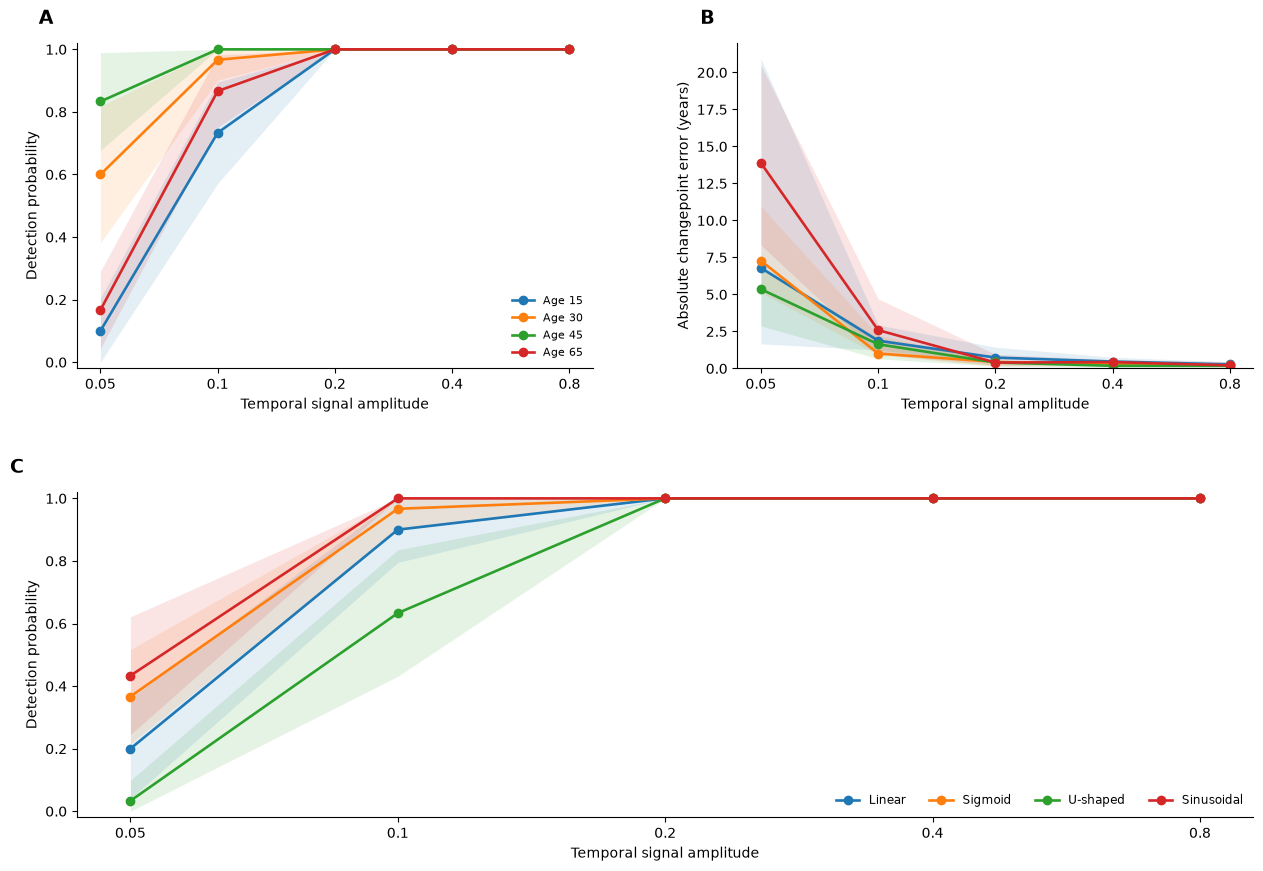

In [13]:
# ============================================================
# 7. Final branch-specific stress-test figure
# ============================================================

fig = plt.figure(
    figsize=(13.0, 8.8)
)

gs = fig.add_gridspec(
    2,
    2,
    left=0.08,
    right=0.985,
    bottom=0.08,
    top=0.96,
    wspace=0.28,
    hspace=0.38,
)


ax_a = fig.add_subplot(
    gs[0, 0]
)

ax_b = fig.add_subplot(
    gs[0, 1]
)

ax_c = fig.add_subplot(
    gs[1, :]
)


# ============================================================
# A. Discrete power by changepoint location
# ============================================================

discrete_power = (
    power_summary.loc[
        power_summary[
            "branch"
        ].eq(
            "discrete"
        )
    ]
    .copy()
)


discrete_geometry_numeric = (
    pd.to_numeric(
        discrete_power[
            "geometry"
        ],
        errors="coerce",
    )
)


for change_age in (
    STEP_LOCATIONS
):

    curve = (
        discrete_power.loc[
            np.isclose(
                discrete_geometry_numeric,
                change_age,
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )


    line, = ax_a.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "mean"
        ],
        marker="o",
        lw=1.9,
        label=(
            f"Age {change_age:g}"
        ),
    )


    ax_a.fill_between(
        curve[
            "signal_strength"
        ],
        curve[
            "ci_low"
        ],
        curve[
            "ci_high"
        ],
        alpha=0.12,
        color=line.get_color(),
        linewidth=0,
    )


ax_a.set_xscale(
    "log",
    base=2,
)

ax_a.set_xticks(
    SIGNAL_STRENGTHS
)

ax_a.set_xticklabels(
    [
        f"{value:g}"
        for value
        in SIGNAL_STRENGTHS
    ]
)

ax_a.set_ylim(
    -0.02,
    1.02,
)

ax_a.set_xlabel(
    "Temporal signal amplitude"
)

ax_a.set_ylabel(
    "Detection probability"
)

ax_a.legend(
    frameon=False,
    fontsize=8,
)


# ============================================================
# B. Discrete changepoint estimation error
# ============================================================

discrete_error_geometry = (
    pd.to_numeric(
        discrete_error_summary[
            "geometry"
        ],
        errors="coerce",
    )
)


for change_age in (
    STEP_LOCATIONS
):

    curve = (
        discrete_error_summary.loc[
            np.isclose(
                discrete_error_geometry,
                change_age,
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )


    line, = ax_b.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "median_error"
        ],
        marker="o",
        lw=1.9,
        label=(
            f"Age {change_age:g}"
        ),
    )


    ax_b.fill_between(
        curve[
            "signal_strength"
        ],
        curve[
            "q25"
        ],
        curve[
            "q75"
        ],
        alpha=0.12,
        color=line.get_color(),
        linewidth=0,
    )


ax_b.set_xscale(
    "log",
    base=2,
)

ax_b.set_xticks(
    SIGNAL_STRENGTHS
)

ax_b.set_xticklabels(
    [
        f"{value:g}"
        for value
        in SIGNAL_STRENGTHS
    ]
)

ax_b.set_ylim(
    bottom=0
)

ax_b.set_xlabel(
    "Temporal signal amplitude"
)

ax_b.set_ylabel(
    "Absolute changepoint error (years)"
)


# ============================================================
# C. Continuous power by trajectory shape
# ============================================================

continuous_power = (
    power_summary.loc[
        power_summary[
            "branch"
        ].eq(
            "continuous"
        )
    ]
    .copy()
)


shape_labels = {
    "linear":
        "Linear",

    "sigmoid":
        "Sigmoid",

    "u_shape":
        "U-shaped",

    "sinusoid":
        "Sinusoidal",
}


for shape in (
    CONTINUOUS_SHAPES
):

    curve = (
        continuous_power.loc[
            continuous_power[
                "geometry"
            ].eq(
                shape
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )


    line, = ax_c.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "mean"
        ],
        marker="o",
        lw=1.9,
        label=(
            shape_labels[
                shape
            ]
        ),
    )


    ax_c.fill_between(
        curve[
            "signal_strength"
        ],
        curve[
            "ci_low"
        ],
        curve[
            "ci_high"
        ],
        alpha=0.12,
        color=line.get_color(),
        linewidth=0,
    )


ax_c.set_xscale(
    "log",
    base=2,
)

ax_c.set_xticks(
    SIGNAL_STRENGTHS
)

ax_c.set_xticklabels(
    [
        f"{value:g}"
        for value
        in SIGNAL_STRENGTHS
    ]
)

ax_c.set_ylim(
    -0.02,
    1.02,
)

ax_c.set_xlabel(
    "Temporal signal amplitude"
)

ax_c.set_ylabel(
    "Detection probability"
)

ax_c.legend(
    frameon=False,
    fontsize=8.5,
    ncol=4,
    loc="lower right",
)


# ============================================================
# Shared cosmetics
# ============================================================

for ax in (
    ax_a,
    ax_b,
    ax_c,
):

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


# ============================================================
# Panel labels
# ============================================================

panel_labels = {
    ax_a: "A",
    ax_b: "B",
    ax_c: "C",
}


for ax, label in panel_labels.items():

    ax.text(
        -0.045,
        1.045,
        label,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=14,
        fontweight="bold",
        clip_on=False,
    )


plt.show()